### Task 1: Baseline CNN Training on MNIST

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
import matplotlib.pyplot as plt


torch.manual_seed(42)
np.random.seed(42)


device = torch.device('cpu')
print(f"Using device: {device}")

transform = transforms.Compose([transforms.ToTensor()])
train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=1000, shuffle=False)


class BaselineCNN(nn.Module):
    def __init__(self):
        super(BaselineCNN, self).__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size=5, padding=2)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=5, padding=2)
        self.pool = nn.MaxPool2d(2, 2)
        self.fc1 = nn.Linear(32 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 10)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))
        x = x.view(-1, 32 * 7 * 7)
        x = self.relu(self.fc1(x))
        x = self.fc2(x)
        return x

model = BaselineCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

print("Training baseline CNN (2 epochs)...")
model.train()
for epoch in range(2):
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
print("done.")


def evaluate_clean(model, loader):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return 100.0 * correct / total

clean_acc = evaluate_clean(model, test_loader)
print(f"Clean test accuracy : {clean_acc:.1f} %")

Using device: cpu


100%|██████████| 9.91M/9.91M [00:00<00:00, 106MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 3.72MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 27.5MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.37MB/s]


Training baseline CNN (2 epochs)...
done.
Clean test accuracy : 98.7 %


### Tasks 2 & 3: FGSM and PGD Attacks Implementation

In [4]:
import torch

def fgsm_attack(images, epsilon, data_grad):

    sign_data_grad = data_grad.sign()

    perturbed_image = images + epsilon * sign_data_grad

    perturbed_image = torch.clamp(perturbed_image, 0, 1)
    return perturbed_image

def pgd_attack(model, images, labels, epsilon, alpha=None, iters=10):
    if alpha is None:
        alpha = epsilon / 4


    perturbed_images = images.clone().detach() + torch.FloatTensor(*images.shape).uniform_(-epsilon, epsilon).to(device)
    perturbed_images = torch.clamp(perturbed_images, 0, 1)

    local_criterion = torch.nn.CrossEntropyLoss()
    for i in range(iters):
        perturbed_images.requires_grad = True
        outputs = model(perturbed_images)
        loss = local_criterion(outputs, labels)

        model.zero_grad()
        loss.backward()

        adv_images = perturbed_images + alpha * perturbed_images.grad.sign()

        eta = torch.clamp(adv_images - images, min=-epsilon, max=epsilon)
        perturbed_images = torch.clamp(images + eta, min=0, max=1).detach()

    return perturbed_images


def evaluate_attack(model, loader, attack_type, epsilon):
    model.eval()
    correct = 0
    total = 0
    local_criterion = torch.nn.CrossEntropyLoss()
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        if epsilon == 0:
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)
            continue

        if attack_type == 'fgsm':
            images.requires_grad = True
            outputs = model(images)
            loss = local_criterion(outputs, labels)
            model.zero_grad()
            loss.backward()
            data_grad = images.grad.data
            perturbed_images = fgsm_attack(images, epsilon, data_grad)
        elif attack_type == 'pgd':
            perturbed_images = pgd_attack(model, images, labels, epsilon, alpha=epsilon/4, iters=10)

        outputs = model(perturbed_images)
        _, predicted = torch.max(outputs.data, 1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)
    return 100.0 * correct / total

### Evaluating Baseline Model and Displaying Outputs

In [3]:
epsilons = [0.00, 0.05, 0.10, 0.20, 0.30]
fgsm_accuracies = []
pgd_accuracies = []

for eps in epsilons:
    f_acc = evaluate_attack(model, test_loader, 'fgsm', eps)
    p_acc = evaluate_attack(model, test_loader, 'pgd', eps)
    fgsm_accuracies.append(f_acc)
    pgd_accuracies.append(p_acc)

print("EPSILON  FGSM_ACC  PGD_ACC")
print("-------------------------------")
for i, eps in enumerate(epsilons):
    print(f"{eps:.2f}     {fgsm_accuracies[i]:.1f} %    {pgd_accuracies[i]:.1f} %")
print("-------------------------------")
print(f"Attack success (eps=0.20): FGSM {100.0 - fgsm_accuracies[3]:.1f} %, PGD {100.0 - pgd_accuracies[3]:.1f} %")

EPSILON  FGSM_ACC  PGD_ACC
-------------------------------
0.00     98.7 %    98.7 %
0.05     93.1 %    91.0 %
0.10     75.2 %    56.3 %
0.20     24.2 %    1.0 %
0.30     5.6 %    0.0 %
-------------------------------
Attack success (eps=0.20): FGSM 75.8 %, PGD 99.0 %


### Task 4: Display 5 Clean Digits vs FGSM Adversarial Versions

In [ ]:

model.eval()
samples_loader = DataLoader(test_dataset, batch_size=5, shuffle=False)
images, labels = next(iter(samples_loader))
images, labels = images.to(device), labels.to(device)

images.requires_grad = True
outputs = model(images)
loss = criterion(outputs, labels)
model.zero_grad()
loss.backward()
data_grad = images.grad.data

perturbed_images = fgsm_attack(images, 0.20, data_grad)
outputs_adv = model(perturbed_images)
_, preds_clean = torch.max(outputs.data, 1)
_, preds_adv = torch.max(outputs_adv.data, 1)


fig, axes = plt.subplots(2, 5, figsize=(12, 6))
for idx in range(5):

    axes[0, idx].imshow(images[idx].squeeze().detach().cpu().numpy(), cmap='gray')
    axes[0, idx].set_title(f"Clean: {labels[idx].item()}\nPred: {preds_clean[idx].item()}")
    axes[0, idx].axis('off')

    axes[1, idx].imshow(perturbed_images[idx].squeeze().detach().cpu().numpy(), cmap='gray')
    axes[1, idx].set_title(f"Adv (eps=0.2): {labels[idx].item()}\nPred: {preds_adv[idx].item()}")
    axes[1, idx].axis('off')

plt.tight_layout()
plt.savefig('clean_vs_adversarial.png')
plt.show()
print("Mis-read digits saved : clean_vs_adversarial.png")

### Task 5: Adversarial Training

In [5]:

adv_model = BaselineCNN().to(device)
adv_optimizer = optim.Adam(adv_model.parameters(), lr=0.001)
local_criterion = nn.CrossEntropyLoss()

print("Fine-tuning model on 50:50 Clean-FGSM Mix (2 epochs)...")
adv_model.train()
for epoch in range(2):
    for batch_images, batch_labels in train_loader:
        batch_images, batch_labels = batch_images.to(device), batch_labels.to(device)

        half_batch = batch_images.size(0) // 2
        clean_images = batch_images[:half_batch]
        clean_labels = batch_labels[:half_batch]

        adv_images = batch_images[half_batch:]
        adv_labels = batch_labels[half_batch:]

        adv_images.requires_grad = True
        outputs_temp = adv_model(adv_images)
        loss_temp = local_criterion(outputs_temp, adv_labels)
        adv_model.zero_grad()
        loss_temp.backward()

        perturbed_adv_images = fgsm_attack(adv_images, 0.20, adv_images.grad.data)


        mixed_images = torch.cat((clean_images, perturbed_adv_images), dim=0)
        mixed_labels = torch.cat((clean_labels, adv_labels), dim=0)

        adv_optimizer.zero_grad()
        mixed_outputs = adv_model(mixed_images)
        mixed_loss = local_criterion(mixed_outputs, mixed_labels)
        mixed_loss.backward()
        adv_optimizer.step()

print("done.")


clean_adv_trained = evaluate_clean(adv_model, test_loader)
fgsm_adv_trained = evaluate_attack(adv_model, test_loader, 'fgsm', 0.20)
pgd_adv_trained = evaluate_attack(adv_model, test_loader, 'pgd', 0.20)

print("\nMODEL           CLEAN     FGSM(0.20)   PGD(0.20)")
print("----------------------------------------------------")
print(f"Baseline        {clean_acc:.1f} %    {fgsm_accuracies[3]:.1f} %      {pgd_accuracies[3]:.1f} %")
print(f"Adversarially   {clean_adv_trained:.1f} %    {fgsm_adv_trained:.1f} %      {pgd_adv_trained:.1f} %")
print("trained")
print("----------------------------------------------------")

clean_change = clean_adv_trained - clean_acc
fgsm_gain = fgsm_adv_trained - fgsm_accuracies[3]
pgd_gain = pgd_adv_trained - pgd_accuracies[3]

print(f"Clean accuracy change : {clean_change:+.1f} %")
print(f"FGSM robustness gain : {fgsm_gain:+.1f} %   PGD gain : {pgd_gain:+.1f} %")

Fine-tuning model on 50:50 Clean-FGSM Mix (2 epochs)...
done.

MODEL           CLEAN     FGSM(0.20)   PGD(0.20)
----------------------------------------------------
Baseline        98.7 %    24.2 %      1.0 %
Adversarially   98.6 %    87.6 %      28.6 %
trained
----------------------------------------------------
Clean accuracy change : -0.1 %
FGSM robustness gain : +63.4 %   PGD gain : +27.6 %


### Task 6: Plot Epsilon vs Accuracy

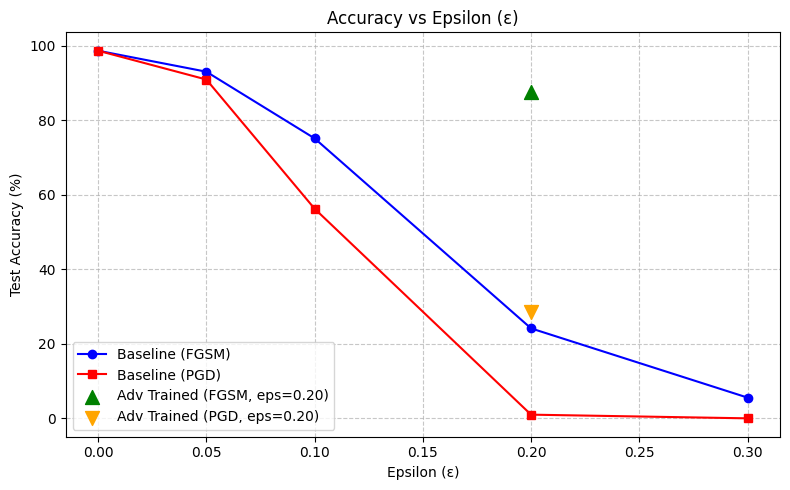

Plot saved : accuracy_vs_epsilon.png


In [6]:
plt.figure(figsize=(8, 5))
plt.plot(epsilons, fgsm_accuracies, 'o-', label='Baseline (FGSM)', color='blue')
plt.plot(epsilons, pgd_accuracies, 's-', label='Baseline (PGD)', color='red')

=0.20
plt.scatter([0.20], [fgsm_adv_trained], color='green', marker='^', s=100, label='Adv Trained (FGSM, eps=0.20)', zorder=5)
plt.scatter([0.20], [pgd_adv_trained], color='orange', marker='v', s=100, label='Adv Trained (PGD, eps=0.20)', zorder=5)

plt.title('Accuracy vs Epsilon (ε)')
plt.xlabel('Epsilon (ε)')
plt.ylabel('Test Accuracy (%)')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.tight_layout()
plt.savefig('accuracy_vs_epsilon.png')
plt.show()
print("Plot saved : accuracy_vs_epsilon.png")